# Cap. 6 · Box-Jenkins con SARIMA (reservas)
*Proyecto DAT 262 · Monitor de estrés cambiario y monetario de Bolivia*

In [1]:
import sys, warnings
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent))
warnings.filterwarnings("ignore")
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from stress_monitor import data, stationarity as stat, markov as mk, forecasting as fc, gap as gp, simulation as sim, demo
plt.rcParams.update({"figure.dpi": 100, "axes.grid": True, "grid.alpha": .3})
m = data.load_monthly(); d = data.load_daily_key()
print("Datos mensuales:", m.index.min().date(), "→", m.index.max().date(), f"({len(m)} meses)")

Datos mensuales: 1989-01-31 → 2026-10-31 (454 meses)


Ciclo de Box-Jenkins: **identificación** (estacionariedad, ACF/PACF), **estimación**, **diagnóstico** y **pronóstico**.

In [2]:
y = fc.log_series(m, 'rib')
print('d sugerido:', fc.choose_d(y), '| D sugerido:', fc.choose_D(y))
print(stat.adf(y)['p_valor'], stat.adf(y.diff().dropna())['p_valor'])

d sugerido: 1 | D sugerido: 0
0.27268438125690775 0.12265215324603113


In [3]:
spec = fc.select_sarima(y); print(spec)
res = fc.fit_sarima(y, spec.order, spec.seasonal_order)
print(fc.diagnostics(res, spec))

SarimaSpec(order=(2, 1, 2), seasonal_order=(0, 0, 0, 12), aic=-839.709677770586)
{'n_resid': 238, 'media_resid': -0.0007187255270998217, 'sd_resid': 0.04781003771536665, 'ljung_box_p_12': 0.00016212931451727204, 'ljung_box_p_24': 0.0005204303149520062, 'jarque_bera_p': 1.3259486557333396e-79, 'asimetria': -0.7919068132933637, 'curtosis': 8.841335502150024, 'residuos_blancos_5%': False}


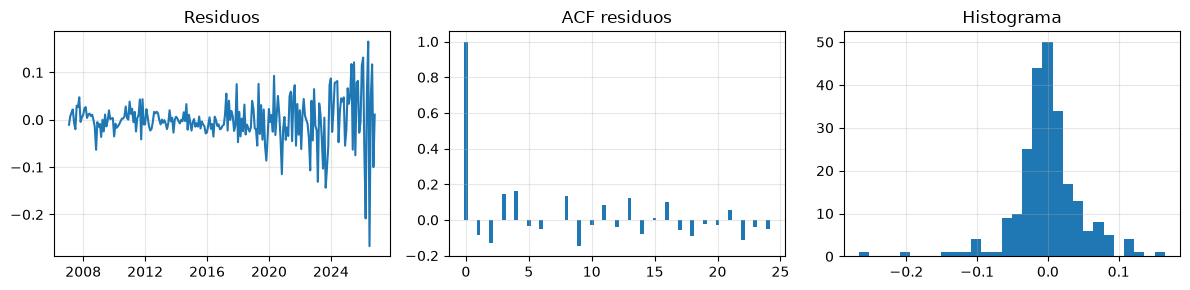

In [4]:
e = pd.Series(res.resid).iloc[fc.BURN_IN:]
fig, ax = plt.subplots(1, 3, figsize=(12, 3))
ax[0].plot(e); ax[0].set_title('Residuos'); a = stat.acf_pacf(e, 24); ax[1].bar(a.lag, a.acf, width=.3); ax[1].set_title('ACF residuos'); ax[2].hist(e, 30); ax[2].set_title('Histograma')
plt.tight_layout()

,media,inf,sup
2026-11-30,4050.0,3697.0,4436.0
2026-12-31,4069.0,3521.0,4702.0
2027-01-31,4128.0,3444.0,4948.0
2027-02-28,4161.0,3348.0,5173.0
2027-03-31,4209.0,3279.0,5404.0
2027-04-30,4247.0,3204.0,5630.0
2027-05-31,4290.0,3139.0,5863.0
2027-06-30,4329.0,3073.0,6097.0
2027-07-31,4369.0,3012.0,6339.0
2027-08-31,4408.0,2950.0,6584.0


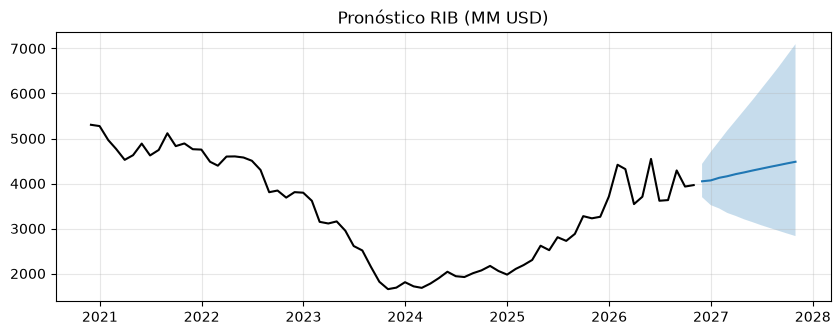

In [5]:
f = fc.forecast_log(res, 12); h = np.exp(y.iloc[-72:])
fig, ax = plt.subplots(figsize=(10, 3.5)); ax.plot(h.index, h, c='k'); ax.plot(f.index, f.media); ax.fill_between(f.index, f['inf'], f['sup'], alpha=.25); ax.set_title('Pronóstico RIB (MM USD)')
f.round(0)

### Validación con ventana móvil (12 orígenes para que el notebook sea rápido)

In [6]:
v = fc.rolling_validation(y, spec, n_origins=12)
v.pivot_table(index='h', columns='modelo', values='MAPE_%').round(2)

modelo,holt_winters,ingenuo,sarima
h,,,
1,9.78,9.03,10.03
3,12.92,12.53,13.00
6,23.22,17.41,22.03
